In [6]:
%load_ext autoreload
%autoreload 2

# 1. Comprensión de los Datos (EDA)

## 1.1 Carga del Dataset y Estructuración del DataFrame

In [8]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Detectar la raíz del proyecto para evitar errores de ModuleNotFoundError
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(PROJECT_ROOT, 'src')):
    PROJECT_ROOT = os.getcwd()

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

print(f"Raíz del proyecto: {PROJECT_ROOT}")

# Importar la función desde el archivo que acabamos de crear
from src.data.preprocess import resize_and_normalize

# Ruta a la carpeta de Kaggle
DATASET_PATH = os.path.join(PROJECT_ROOT, "data_raw/kaggle/archive")

# Indexar las imágenes de Good y Bad Quality
image_data = []
for main_folder in ['Bad Quality_Fruits', 'Good Quality_Fruits']:
    folder_path = os.path.join(DATASET_PATH, main_folder)
    if os.path.exists(folder_path):
        for subfolder in os.listdir(folder_path):
            subfolder_path = os.path.join(folder_path, subfolder)
            if os.path.isdir(subfolder_path):
                for file in os.listdir(subfolder_path):
                    if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                        full_path = os.path.join(subfolder_path, file)
                        quality = "Good" if "Good" in main_folder else "Bad"
                        fruit = subfolder.replace("_Bad", "").replace("_Good", "")
                        image_data.append({
                            "path": full_path,
                            "fruit": fruit,
                            "quality": quality,
                            "label": f"{fruit}_{quality}"
                        })

df = pd.DataFrame(image_data)
print(f"Total de imágenes registradas: {len(df)}")

Raíz del proyecto: /home/dia/Documentos/La U/apo3/proyectoFinal/repo/ProyectoFinalAPO3
Total de imágenes registradas: 18452


## 1.2 Análisis de Distribución de Clases y Evaluación de Desbalanceo

=== DISTRIBUCIÓN DE CLASES Y EVALUACIÓN DE DESBALANCEO ===
quality       Bad  Good  Total  Ratio_Bad_Good
fruit                                         
Apple        1141  1149   2290            0.99
Banana       1087  1113   2200            0.98
Guava        1129  1152   2281            0.98
Lime         1085  1094   2179            0.99
Orange       1159  1216   2375            0.95
Pomegranate  1187  5940   7127            0.20


/tmp/ipykernel_24491/1165995738.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='quality', palette=['#2ecc71', '#e74c3c'], ax=axes[0])


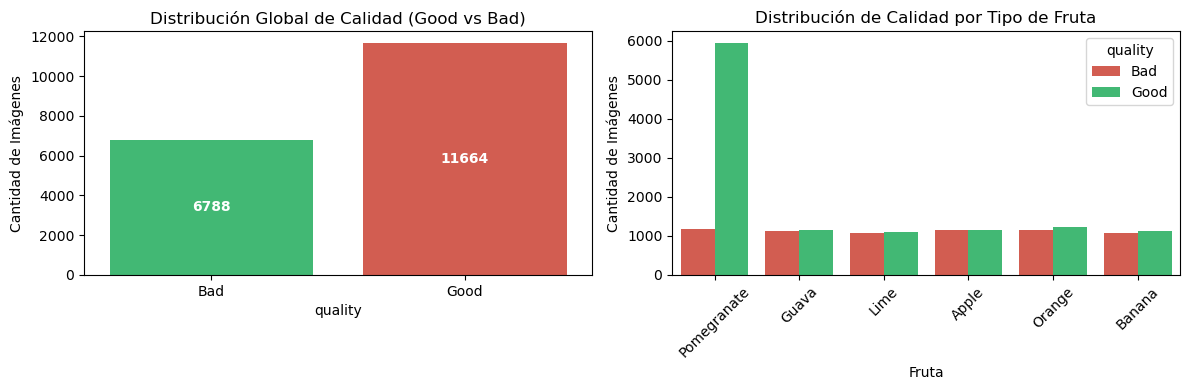

In [14]:
import seaborn as sns

# 1. Conteo exacto por clase y fruta
class_counts = df.groupby(['fruit', 'quality']).size().unstack(fill_value=0)
class_counts['Total'] = class_counts.sum(axis=1)
class_counts['Ratio_Bad_Good'] = (class_counts['Bad'] / class_counts['Good']).round(2)

print("=== DISTRIBUCIÓN DE CLASES Y EVALUACIÓN DE DESBALANCEO ===")
print(class_counts)

# 2. Visualización para el Informe (Graficos estilizados)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico A: Balance General Good vs Bad
sns.countplot(data=df, x='quality', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title("Distribución Global de Calidad (Good vs Bad)")
axes[0].set_ylabel("Cantidad de Imágenes")
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# Gráfico B: Desbalance por Tipo de Fruta
sns.countplot(data=df, x='fruit', hue='quality', palette=['#e74c3c', '#2ecc71'], ax=axes[1])
axes[1].set_title("Distribución de Calidad por Tipo de Fruta")
axes[1].set_xlabel("Fruta")
axes[1].set_ylabel("Cantidad de Imágenes")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 1.3 Exploración Física de Imágenes y Validación del Preprocesamiento

=== Propiedades de la Matriz Preprocesada ===
Dimensiones (Shape): (128, 128, 3)
Tipo de dato: float32
Píxel Mínimo: 0.00
Píxel Máximo: 1.00


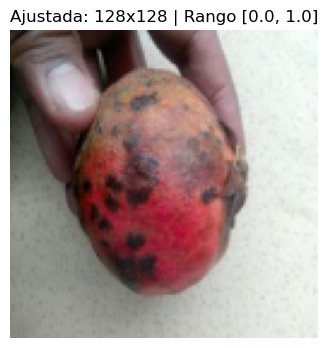

In [9]:
# Tomar la primera imagen como muestra
sample_path = df['path'].iloc[0]

# Aplicar el preprocesamiento
processed_img = resize_and_normalize(sample_path, target_size=(128, 128))

# Imprimir verificaciones numéricas para el informe
print("=== Propiedades de la Matriz Preprocesada ===")
print(f"Dimensiones (Shape): {processed_img.shape}")
print(f"Tipo de dato: {processed_img.dtype}")
print(f"Píxel Mínimo: {processed_img.min():.2f}")
print(f"Píxel Máximo: {processed_img.max():.2f}")

# Mostrar la imagen procesada
plt.figure(figsize=(4, 4))
plt.imshow(processed_img)
plt.title(f"Ajustada: 128x128 | Rango [{processed_img.min():.1f}, {processed_img.max():.1f}]")
plt.axis('off')
plt.show()

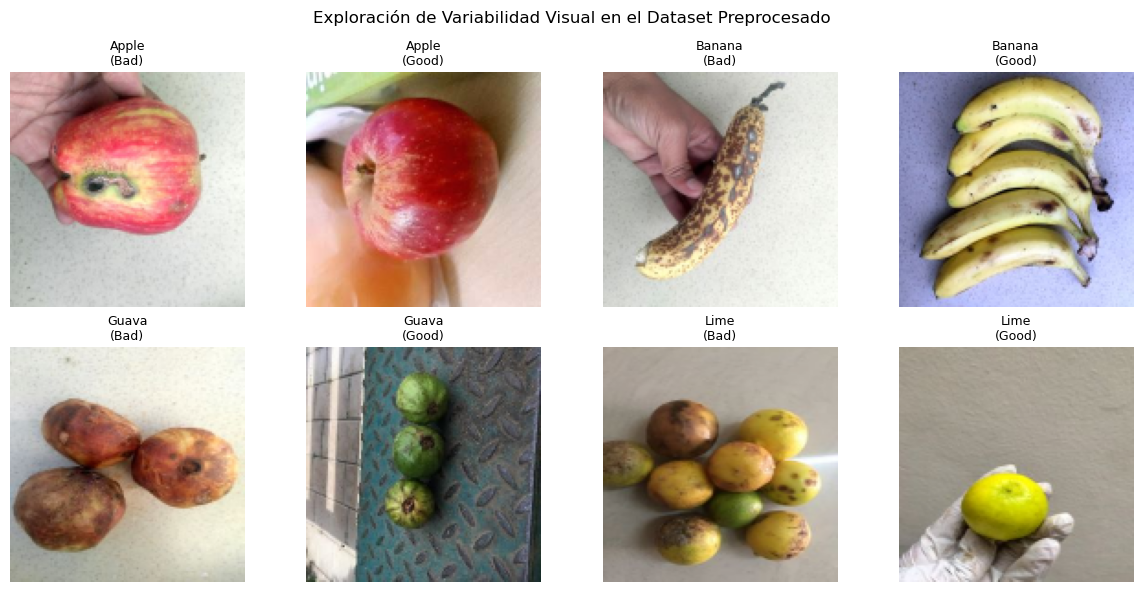

In [16]:
# Mostrar rejilla de variabilidad (4 frutas al azar: Good vs Bad)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
sample_fruits = df.groupby(['fruit', 'quality']).sample(1, random_state=42).head(8)

for idx, (_, row) in enumerate(sample_fruits.iterrows()):
    ax = axes[idx // 4, idx % 4]
    img = resize_and_normalize(row['path'])
    ax.imshow(img)
    ax.set_title(f"{row['fruit']}\n({row['quality']})", fontsize=9)
    ax.axis('off')

plt.suptitle("Exploración de Variabilidad Visual en el Dataset Preprocesado", fontsize=12)
plt.tight_layout()
plt.show()

## 1.4 Análisis Exploratorio de Características Extraídas (Firmas de Color)

=== Extracción de Características Exitosa ===
Longitud del vector de características: 512
Primeros 10 valores del vector: [0.0787 0.0004 0.     0.     0.     0.     0.     0.     0.0017 0.    ]


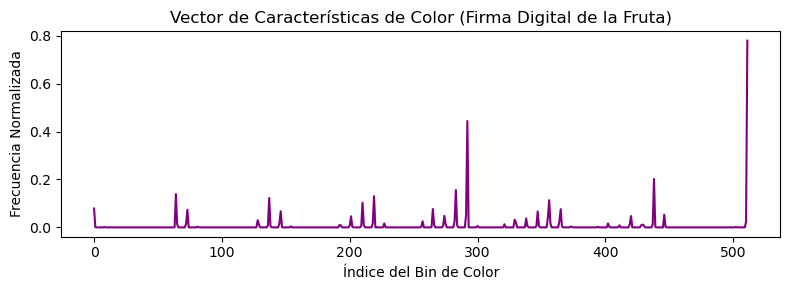

In [13]:
import importlib
import numpy as np
import src.data.preprocess as preprocess

# Forzar a Python a recargar el archivo preprocess.py desde el disco
importlib.reload(preprocess)

# Extraer el vector de características de la imagen de muestra
features = preprocess.extract_combined_features(sample_path)

print("=== Extracción de Características Exitosa ===")
print(f"Longitud del vector de características: {len(features)}")
print(f"Primeros 10 valores del vector: {np.round(features[:10], 4)}")

# Graficar la firma de color
plt.figure(figsize=(8, 3))
plt.plot(features, color='purple', linewidth=1.5)
plt.title("Vector de Características de Color (Firma Digital de la Fruta)")
plt.xlabel("Índice del Bin de Color")
plt.ylabel("Frecuencia Normalizada")
plt.tight_layout()
plt.show()

### Extracción de Características de Color

En esta etapa se implementó la extracción manual de características orientada a los modelos de Machine Learning tradicionales (KNN, SVM, Random Forest). 

#### 1. Justificación y Reducción de Dimensionalidad
* **Dimensión de Entrada:** La imagen preprocesada de $128 \times 128 \times 3$ contiene un total de $49,152$ valores de píxeles independientes.
* **Histograma Tridimensional (RGB):** Se configuró una discretización en 8 intervalos (*bins*) por cada uno de los tres canales de color ($R, G, B$). El espacio vectorial resultante tiene una dimensión de:
  $$\text{Dimensión} = Bins_R \times Bins_G \times Bins_B = 8 \times 8 \times 8 = 512 \text{ características}$$
* **Compresión:** Se logró una **reducción de dimensionalidad del 98.96%**, pasando de $49,152$ a $512$ descriptores numéricos normalizados $\sum_{i=1}^{512} x_i = 1.0$.

#### 2. Significado Físico de la Firma Digital
* **Eje X (Índice del Bin):** Representa cada combinación única de color en el espacio tridimensional RGB.
* **Eje Y (Frecuencia Normalizada):** Representa la proporción de píxeles de la fruta que se concentran en dicha combinación tonal.
* **Picos/Crestas:** Los picos prominentes (como el observado cerca del bin 300 y 512) representan la firma espectral de la fruta: los colores dominantes de la cáscara y la presencia de zonas oscuras/manchas causadas por defectos o podredumbre.

> **Conclusión para la Fase de Modelado:** Este vector de 512 características servirá como la matriz de entrada $X$ para alimentar clasificadores tradicionales de rápida ejecución, permitiendo evaluar el desempeño de algoritmos geométricos y probabilísticos antes de abordar arquitecturas más complejas como las Redes Neuronales Convolucionales (CNN).

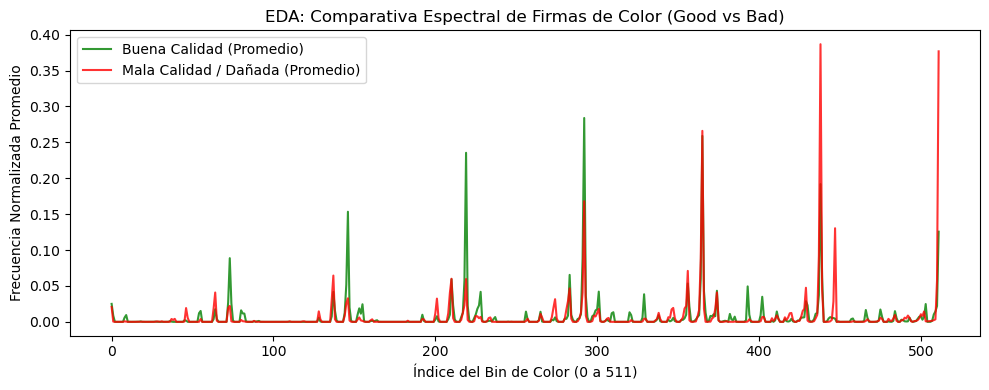

In [17]:
# Tomar muestra representativa de 50 imágenes Good y 50 Bad
good_paths = df[df['quality'] == 'Good']['path'].sample(50, random_state=42)
bad_paths = df[df['quality'] == 'Bad']['path'].sample(50, random_state=42)

# Extraer histogramas
good_feats = np.mean([preprocess.extract_combined_features(p) for p in good_paths], axis=0)
bad_feats = np.mean([preprocess.extract_combined_features(p) for p in bad_paths], axis=0)

# Graficar firmas de color promedio
plt.figure(figsize=(10, 4))
plt.plot(good_feats, color='green', label='Buena Calidad (Promedio)', alpha=0.8, linewidth=1.5)
plt.plot(bad_feats, color='red', label='Mala Calidad / Dañada (Promedio)', alpha=0.8, linewidth=1.5)
plt.title("EDA: Comparativa Espectral de Firmas de Color (Good vs Bad)")
plt.xlabel("Índice del Bin de Color (0 a 511)")
plt.ylabel("Frecuencia Normalizada Promedio")
plt.legend()
plt.tight_layout()
plt.show()